# 03 — Pemeriksaan kualitas data

Pada tahap ini saya mengecek data yang berpotensi memengaruhi rekomendasi, seperti metadata kosong, judul ganda, ISBN ganda, dan tahun tidak wajar. Saya tidak langsung menghapus baris duplikat karena beberapa buku mungkin merupakan edisi berbeda.

## 1. Memuat dataset untuk audit

In [1]:
from pathlib import Path
import re, html, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'data' / 'dataset_buku_2000.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'dataset_buku_2000.csv').exists(), 'Buka folder utama proyek atau notebook dari subfolder notebooks.'
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
FIG = ROOT / 'figures'
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
books = pd.read_csv(DATA / 'dataset_buku_2000.csv', dtype=str).fillna('')
comps = pd.read_csv(DATA / 'competencies_green.csv', dtype=str).fillna('')
print(f'Buku: {len(books):,} | Kompetensi: {len(comps)}')

Buku: 973 | Kompetensi: 67


## 2. Menghitung nilai kosong per kolom

,kolom,jumlah_kosong,persentase_kosong
6,isbn,296,30.42
0,book_id,0,0.00
2,tahun,0,0.00
1,judul,0,0.00
3,abstrak,0,0.00
4,kategori_buku,0,0.00
5,author,0,0.00
7,bahasa,0,0.00


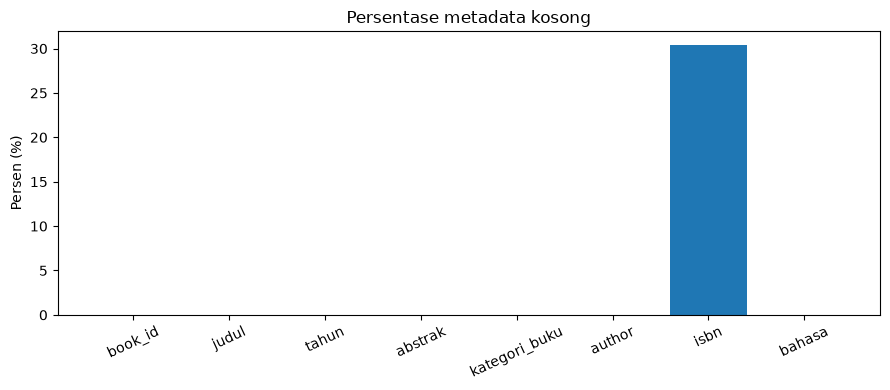

In [2]:
kolom_diperiksa = ['book_id','judul','tahun','abstrak','kategori_buku','author','isbn','bahasa']
audit = pd.DataFrame([{'kolom':k,'jumlah_kosong':int(books[k].str.strip().eq('').sum()),
     'persentase_kosong':round(books[k].str.strip().eq('').mean()*100,2)} for k in kolom_diperiksa])
display(audit.sort_values('jumlah_kosong',ascending=False))
audit.to_csv(OUT/'audit_kualitas.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4));ax.bar(audit.kolom,audit.persentase_kosong)
ax.set(title='Persentase metadata kosong',ylabel='Persen (%)');plt.xticks(rotation=25)
plt.tight_layout();plt.savefig(FIG/'03_kosong.png',dpi=160);plt.show()

## 3. Periksa duplikasi judul dan ISBN

In [3]:
def normalisasi_judul(teks):
    return re.sub(r'[^a-z0-9]', '', str(teks).lower())
books['judul_kunci'] = books.judul.map(normalisasi_judul)
books['isbn_kunci'] = books.isbn.str.replace(r'[^0-9Xx]','',regex=True).str.upper()
judul_ganda = books[books.judul_kunci.ne('') & books.judul_kunci.duplicated(keep=False)]
isbn_ganda = books[books.isbn_kunci.ne('') & books.isbn_kunci.duplicated(keep=False)]
print('Baris dengan judul berulang:',len(judul_ganda))
print('Baris dengan ISBN berulang:',len(isbn_ganda))
display(judul_ganda[['book_id','judul','tahun','isbn']].head(15))
judul_ganda[['book_id','judul','tahun','isbn']].to_csv(OUT/'audit_duplikasi_judul.csv',index=False)

Baris dengan judul berulang: 64
Baris dengan ISBN berulang: 0


,book_id,judul,tahun,isbn
61,BK00062,Customer Relationship Management,2003,9780130352118
64,BK00065,Customer Relationship Management,2023,9781529613346
69,BK00070,Customer Relationship Management,2006,
70,BK00071,Customer Relationship Management,2001,
71,BK00072,Customer Relationship Management,2002,9780130990693
79,BK00080,Purchasing and Supply Management,1997,9780412106019
80,BK00081,Purchasing and Supply Management,2002,
83,BK00084,Purchasing and Supply Management,2007,
85,BK00086,Leading Procurement Strategy,2018,9780749481650
182,BK00183,Organizational Behavior,2009,9788122425703


## 4. Menentukan tindakan untuk data berkualitas rendah
Abstrak kosong ditandai dan tidak dikarang. Informasi kualitas ini akan dipakai saat memeriksa rekomendasi.

In [4]:
tahun_num=pd.to_numeric(books.tahun,errors='coerce')
flag=pd.DataFrame({'book_id':books.book_id,
 'judul_kosong':books.judul.str.strip().eq(''),
 'abstrak_kosong':books.abstrak.str.strip().eq(''),
 'abstrak_pendek':books.abstrak.fillna('').str.split().map(len).lt(30),
 'tahun_tidak_valid':tahun_num.notna() & ~tahun_num.between(1450,2100),
 'judul_berulang':books.judul_kunci.ne('') & books.judul_kunci.duplicated(keep=False)})
flag['butuh_review'] = flag.drop(columns='book_id').any(axis=1)
display(flag.sum(numeric_only=True).to_frame('jumlah'))
flag.to_csv(OUT/'flag_kualitas_buku.csv',index=False)
assert flag.book_id.nunique()==len(books)

,jumlah
judul_kosong,0
abstrak_kosong,0
abstrak_pendek,65
tahun_tidak_valid,0
judul_berulang,64
butuh_review,127


## 5. Menjelaskan keputusan audit
Duplikat judul ditangani saat menyusun Top 10 agar edisi yang sama tidak memenuhi ranking. Dataset asli dipertahankan, sehingga setiap keputusan tetap bisa dilacak.

In [5]:
print('Total data yang tidak dihapus:',len(books))
print('Jumlah buku yang mendapat setidaknya satu flag audit:',int(flag.butuh_review.sum()))
print('File audit tersimpan:',OUT/'flag_kualitas_buku.csv')

Total data yang tidak dihapus: 973
Jumlah buku yang mendapat setidaknya satu flag audit: 127
File audit tersimpan: c:\Users\AUREL ELVIOLITA\Downloads\BPJS_Book_Recommendation\Book_Recommendation\outputs\flag_kualitas_buku.csv


## Kesimpulan tahap
Masalah kualitas sudah dicatat per buku dan per kolom. Notebook preprocessing akan membersihkan teks tanpa mengubah identitas buku atau menyembunyikan metadata yang masih kosong.